# Predicting Bench Press Strength Using Machine Learning

## 1. Introduction

The goal of our project is to predict a powerlifter's best bench press in kilograms. We will produce this prediction through using various input features such as bodyweight, sex, and age.

We will investigate whether including the features age and sex along with bodyweight improves prediction accuracy.

This project will be using regression as we are trying to predict a continuous numerical value. We will use the following two algorithms:
- Linear regression (implemented from scratch)
- Random Forest Regressor

## 2. Dataset Preparation

Before we can begin training our models we must first prepare the data. We will load, inspect, and clean the dataset. 

In [2]:
import pandas as pd

df = pd.read_csv("Dataset/openpowerlifting-latest/openpowerlifting-2026-09-19/openpowerlifting-2026-09-19-ed07773f.csv")

df.head()

/tmp/ipykernel_223926/2131738008.py:3: DtypeWarning: Columns (33: State, 35: ParentFederation, 38: MeetState) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Dataset/openpowerlifting-latest/openpowerlifting-2026-09-19/openpowerlifting-2026-09-19-ed07773f.csv")


,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
0,E.S. Denisenko,F,B,Raw,28.5,24-34,24-39,Open,67.3,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
1,I.S. Lebetskaya,F,B,Raw,43.5,40-44,40-49,Open,73.2,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
2,K. Yakimovich,F,B,Raw,26.5,24-34,24-39,Open,60.6,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
3,A.G. Golneva,F,B,Raw,19.5,20-23,19-23,Juniors 17-21,50.3,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes
4,E.V. Marunevskaya,F,B,Raw,19.5,20-23,19-23,Juniors 17-21,63.7,NaN,...,Belarus,NaN,GSF-Belarus,NaN,2019-06-22,Belarus,NaN,Luninets,Bison Power Cup,Yes


### Initial Data Exploration

Before we begin cleaning the dataset we will start by examining the data's structure and contents. We will investigate the total number of rows and columns, available features, and any possible data quality issues.

This exploration will help determine which data is relevant for our model as well as what preprocessing is needed.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (4034178, 42)

Columns:
['Name', 'Sex', 'Event', 'Equipment', 'Age', 'AgeClass', 'BirthYearClass', 'Division', 'BodyweightKg', 'WeightClassKg', 'Squat1Kg', 'Squat2Kg', 'Squat3Kg', 'Squat4Kg', 'Best3SquatKg', 'Bench1Kg', 'Bench2Kg', 'Bench3Kg', 'Bench4Kg', 'Best3BenchKg', 'Deadlift1Kg', 'Deadlift2Kg', 'Deadlift3Kg', 'Deadlift4Kg', 'Best3DeadliftKg', 'TotalKg', 'Place', 'Dots', 'Wilks', 'Glossbrenner', 'Goodlift', 'Tested', 'Country', 'State', 'Federation', 'ParentFederation', 'Date', 'MeetCountry', 'MeetState', 'MeetTown', 'MeetName', 'Sanctioned']


### Examining Categorical Variables

The dataset consisted of 4,034,178 entries and 42 columns. We will examine the values within Equipment, Event, and Sex columns in order to help in understanding how the data is categorized. This will help determine which entries are suitable for our project.

In [4]:
print("Equipment categories:")
print(df["Equipment"].value_counts(dropna=False))

print("\nEvent categories:")
print(df["Event"].value_counts(dropna=False))

print("\nSex categories:")
print(df["Sex"].value_counts(dropna=False))

Equipment categories:
Equipment
Raw           1921815
Single-ply    1415253
Unlimited      324336
Wraps          241456
Multi-ply      131199
Straps            119
Name: count, dtype: int64

Event categories:
Event
SBD    2913631
B       799289
D       218889
BD       75753
S        19943
SB        4185
SD        2488
Name: count, dtype: int64

Sex categories:
Sex
M     2906204
F     1127775
Mx        199
Name: count, dtype: int64


### Findings from Categorical Data Exploration

The dataset contains six different equipment categories. For our project we want to focus on unequipped lifting which would be the Raw category.

The Raw category contains a total of 1,921,815 entries. We will use only entries classified as Raw. This will help prevent equipped lifting from influencing our predictions.

We examined the various event categories as well. We will include all events that include bench press which will be the following:
- SBD (Squat, Bench, Deadlift)
- B (Bench)
- BD (Bench, Deadlift)
- SB (Squat, Bench)

The sex column contains a total of three categories which are M (Male), F (Female), and Mx (Mix). The Mx category only contains 199 entries so we will consider how to handle this category during preprocessing.

### Filtering the Dataset

Based on the initial exploration we will now filter the dataset to only include the RAW category and within the RAW category we will filter for only events containing bench press as discussed above. 

In [5]:
# Keep only raw lifting entries involving bench press
raw_df = df[
    (df["Equipment"] == "Raw") &
    (df["Event"].isin(["SBD", "B", "BD", "SB"]))
].copy()

print("Original entries:", len(df))
print("Filtered entries:", len(raw_df))

Original entries: 4034178
Filtered entries: 1745981


### Filtered dataset findings

Filtering the dataset reduced the entries from 4,034,178 entries to 1,745,981 entires.

### Checking for Missing Values

Now that the dataset is filtered we will check for any missing values.

The relevant columns for our predictions are:
- BodyweightKg
- Age
- Sex
- Best3BenchKg (Best bench of 3 attempts)

These are the columns we will inspect for missing values.

In [6]:
# Columns relevant to our prediction
columns = ["BodyweightKg", "Age", "Sex", "Best3BenchKg"]

# Count missing values in each column
print(raw_df[columns].isnull().sum())

BodyweightKg      6858
Age             257462
Sex                  0
Best3BenchKg     46683
dtype: int64


### Missing value Findings

After checking fro missing values we can see that BodyweightKg and Best3BenchKg have few missing values in relation to the total dataset. The Age column however has a larger proportion of missing data with approximately 14.75% of entries missing age data. The Sex column contains zero missing entries. 

Given the large size of the dataset we have decided to remove all entries with missing values including the missing Age entries. This will still leave sufficient data for training and evaluating the models.

Removing age entries may however affect how representative the final dataset is. 

### Data Validation

Before we begin cleaning the dataset we will examine the values for age, bodyweight, and best bench press.

We will check for invalid or unusual values as well as the minimum and maximum values. 

This will help determine determine what exactly we should remove and determine which records will be suitable for our models.

In [7]:
# Numerical columns to validate
numeric_cols = ["Age", "BodyweightKg", "Best3BenchKg"]

# Display descriptive statistics
display(raw_df[numeric_cols].describe())

# Count zero or negative values
print("Zero or negative values:")
print((raw_df[numeric_cols] <= 0).sum())

,Age,BodyweightKg,Best3BenchKg
count,1.488519e+06,1.739123e+06,1.699298e+06
mean,3.043370e+01,8.390345e+01,1.123506e+02
std,1.309575e+01,2.167729e+01,4.645848e+01
min,0.000000e+00,1.642000e+01,-3.150000e+02
25%,2.050000e+01,6.766000e+01,7.250000e+01
50%,2.650000e+01,8.165000e+01,1.125000e+02
75%,3.700000e+01,9.720000e+01,1.450000e+02
max,1.055000e+02,2.850000e+02,3.550000e+02


Zero or negative values:
Age                2
BodyweightKg       0
Best3BenchKg    1404
dtype: int64


### Data Validation Findings

Two of the validated columns contain values that are either zero or negative. For Age this means the entries are invalid and thus will be removed. For the best bench column the zero values may be real values but since our goal is to predict successful bench press results, these entries will be excluded. 

The Age column contained a maximum recorded age of 105.5 years which is unusually high. This value should be investigated further.

Bodyweight ranged from 16.42 kg up to 285 kg. These values are extreme but are not necessarily incorrect. Bodyweight did not contain any zero or negative entries.

### Investigating Unusual Ages

In [8]:
# Identify entries with unusually low or high ages
young_lifters = raw_df[raw_df["Age"] < 10]
old_lifters = raw_df[raw_df["Age"] > 90]

print("Entries with age below 10:", len(young_lifters))
print("Entries with age above 90:", len(old_lifters))

# Examine the relevant information
print("\nYoungest lifters:")
display(young_lifters[["Age", "BodyweightKg", "Best3BenchKg"]].sort_values("Age").head(10))

print("\nOldest lifters:")
display(old_lifters[["Age", "BodyweightKg", "Best3BenchKg"]].sort_values("Age", ascending=False).head(10))

Entries with age below 10: 2212
Entries with age above 90: 66

Youngest lifters:


,Age,BodyweightKg,Best3BenchKg
2357757,0.0,90.0,167.50
2357756,0.0,90.0,167.50
112,0.5,125.0,145.00
152224,0.5,52.0,35.00
2354956,0.5,110.0,145.15
260,0.5,125.0,145.00
159701,0.5,67.5,30.00
523694,0.5,125.0,197.50
2298566,0.5,125.0,170.10
2318338,0.5,NaN,158.76



Oldest lifters:


,Age,BodyweightKg,Best3BenchKg
3398006,105.5,123.83,127.50
3435152,99.0,83.85,50.00
557841,98.0,67.50,27.22
3434422,98.0,74.80,75.00
3550514,97.5,70.00,115.00
3550521,97.5,70.00,115.00
3435468,97.0,79.30,55.00
3435298,97.0,80.01,60.00
2214629,97.0,80.85,60.00
559883,97.0,75.00,28.12


### Unusual Age Findings

Upon investigation we have decided to restrict the dataset to lifters in the range of 10 to 100 years. This is due to multiple unrealistic age values such as 0 and 0.5 years and some of these entries having recorded unusually high bodyweight and bench press results.

## Data Cleaning

We will now begin cleaning our data

The following cleaning steps will be applied:

- Keep only the columns needed for our predictions.
- Remove entries with missing values in these columns.
- Restrict ages to the range of 10–100 years.
- Remove entries with zero or negative bodyweight or bench press results.
- Remove Sex entries with a value of Mx (Due to small sample size)

This will provide a more reliable dataset for training and
evaluating our regression models.

In [9]:
# Select the columns needed for our models
columns = ["BodyweightKg", "Age", "Sex", "Best3BenchKg"]

clean_df = raw_df[columns].copy()

# Remove entries with missing values
clean_df = clean_df.dropna()

# Remove invalid values and exclude Mx
clean_df = clean_df[
    (clean_df["Age"].between(10, 100)) &
    (clean_df["BodyweightKg"] > 0) &
    (clean_df["Best3BenchKg"] > 0) &
    (clean_df["Sex"].isin(["M", "F"]))
].copy()

# Display cleaning results
print("Entries before cleaning:", len(raw_df))
print("Entries after cleaning:", len(clean_df))
print("Entries removed:", len(raw_df) - len(clean_df))

display(clean_df.head())

Entries before cleaning: 1745981
Entries after cleaning: 1444267
Entries removed: 301714


,BodyweightKg,Age,Sex,Best3BenchKg
1,73.2,43.5,F,90.0
2,60.6,26.5,F,45.0
3,50.3,19.5,F,35.0
4,63.7,19.5,F,42.5
5,82.0,30.5,M,132.5


### Cleaning results

Cleaning the data resulted in a total of 1,444,267 entries from 1,745,981 entries. This totaled to 301,714 entries removed.

After cleaning we are left with more than enough sufficient data for our models. The remaining data contains complete records with bodyweight, age, sex, and best bench press. 

### Selecting the Final Dataset

We will randomly select 50,000 of the 1,444,267 entries for our project. This will provide enough data and keep computation manageable.

A fixed seed will ensure the same sample can be reproduced.

In [10]:
# Randomly select 50,000 entries
sample_df = clean_df.sample(n=50000, random_state=42)

# Save the dataset
sample_df.to_csv("bench_press_sample.csv", index=False)

print("Final dataset size:", sample_df.shape)
display(sample_df.head())

Final dataset size: (50000, 4)


,BodyweightKg,Age,Sex,Best3BenchKg
2992853,103.60,29.0,M,215.0
2992607,70.90,49.0,F,70.0
3009943,81.40,21.0,F,80.5
1364327,74.80,27.0,F,60.0
3445583,64.12,20.5,F,65.0


### Splitting the dataset

Before training we will split the dataset. We will split the dataset into both training and testing sets.

80% of the data will be used for training and 20% will be used for testing. Both algorithms will use the same split to ensure a fair comparison.

In [11]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing
train_df, test_df = train_test_split(
    sample_df,
    test_size=0.2,
    random_state=42,
    stratify=sample_df["Sex"]
)

print("Training entries:", len(train_df))
print("Testing entries:", len(test_df))

Training entries: 40000
Testing entries: 10000


### Training and Testing split findings

Splitting the dataset using 80% training data and 20% testing data resulted in a total of 40000 training entries and 10000 testing entries.

We stratified by sex in order to maintain similar proportions of male and female lifters in both datasets.

In [12]:
# Save the training and testing datasets
train_df.to_csv("bench_train.csv", index=False)
test_df.to_csv("bench_test.csv", index=False)

## Linear Regression implementation

We will implement linear regression from scratch to predict a lifter's best bench press result.

We will have two feature configurations. The first will use only bodyweight while the second will use bodyweight, age, and sex. Comparing these configurations will help us in investigating whether including age and sex increases prediction accuracy.

### Preparing Input Features and Target Values

We will start by separating the input features from the target variable.

Linear regression uses numerical targets so we will use binary encoding where 0 will represent female and 1 will represent male.

In [14]:
import numpy as np

# Model 1: Bodyweight only
X_train_body = train_df[["BodyweightKg"]].to_numpy()
X_test_body = test_df[["BodyweightKg"]].to_numpy()

# Model 2: Bodyweight, Age, and Sex
X_train_full = train_df[["BodyweightKg", "Age"]].copy()
X_test_full = test_df[["BodyweightKg", "Age"]].copy()

# Encode Sex numerically
X_train_full["Sex"] = train_df["Sex"].map({"F": 0, "M": 1})
X_test_full["Sex"] = test_df["Sex"].map({"F": 0, "M": 1})

# Convert to NumPy arrays
X_train_full = X_train_full.to_numpy()
X_test_full = X_test_full.to_numpy()

# Target variable for both models
y_train = train_df["Best3BenchKg"].to_numpy()
y_test = test_df["Best3BenchKg"].to_numpy()

# Check the dimensions
print("Bodyweight only training:", X_train_body.shape)
print("Full feature training:", X_train_full.shape)
print("Training targets:", y_train.shape)

Bodyweight only training: (40000, 1)
Full feature training: (40000, 3)
Training targets: (40000,)


### Feature Scaling

We will now standardize the input features so they are on comparable numerical scales. This will make optimization easier for gradient descent. We will do this by using StandardScaler().

In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale bodyweight features
body_scaler = StandardScaler()

X_train_body_scaled = body_scaler.fit_transform(X_train_body)
X_test_body_scaled = body_scaler.transform(X_test_body)

# Scale all three features
full_scaler = StandardScaler()

X_train_full_scaled = full_scaler.fit_transform(X_train_full)
X_test_full_scaled = full_scaler.transform(X_test_full)

### Implementing Linear Regression From Scratch

We will not be using a pre build regression model. We will instead build the model from scratch using NumPy.

We will use gradient descent in order to determine coefficients that will minimize mean squared error or MSE for short between the predicted and actual bench press results.

During training the model will repeatedly calculate predictions. It will measure errors and continuously update coefficients to improve prediction accuracy.

In [16]:
class LinearRegressionScratch:
    def __init__(self, learning_rate=0.1, epochs=500):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize coefficients
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.epochs):
            # Calculate predictions and errors
            predictions = X @ self.weights + self.bias
            errors = predictions - y

            # Calculate gradients
            dw = (2 / n_samples) * (X.T @ errors)
            db = (2 / n_samples) * errors.sum()

            # Update coefficients
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # Record training error
            self.loss_history.append(np.mean(errors ** 2))

    def predict(self, X):
        return X @ self.weights + self.bias

In [ ]:
# Train bodyweight only model
body_model = LinearRegressionScratch()
body_model.fit(X_train_body_scaled, y_train)

# Train full feature model
full_model = LinearRegressionScratch()
full_model.fit(X_train_full_scaled, y_train)

# Display final training errors
print("Bodyweight only training MSE:", round(body_model.loss_history[-1], 2))
print("Full feature training MSE:", round(full_model.loss_history[-1], 2))

Bodyweight only training MSE: 1211.49
Full feature training MSE: 768.7


### Linear Regression Training Findings

The Bodyweight Only Training model had a MSE of 1211.49 while the Full Feature Training model had a MSE of 768.7. This indicates the full feature model had approximately a 36.5% lower training error. This suggests including age and sex does in fact increase accuracy. 

However, these results are not final. Both models still need to be evaluated on test data to determine how well they perform on unseen data.

### Checking Gradient Descent Convergence

We will plot the MSE across the 500 epochs for both models. This is in order to examine how the error changes during training.

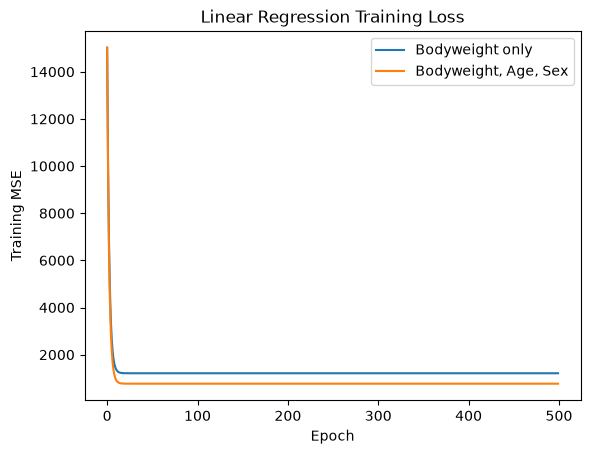

In [21]:
import matplotlib.pyplot as plt

plt.plot(body_model.loss_history, label="Bodyweight only")
plt.plot(full_model.loss_history, label="Bodyweight, Age, Sex")

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Linear Regression Training Loss")
plt.legend()
plt.show()

### Gradient Descent Convergence Findings

As you can see in the graph from about epoch 0-10 the Training MSE was very high. At around epoch 10-20 and onward the Training MSE stabilized as seen in the flattening curve. This is indicative of gradient descent being converged.

These results suggest 500 epochs were sufficient for both models to converge. The full feature model achieved a lower training error.

### Evaluating Linear Regression Models

We will now evaluate performance using the test dataset. 

Three metrics will be used:
- MAE: Mean Absolute Error which will measure the absolute difference between predicted and actual bench press results
- RMSE: Root Mean Squared Error which will indicate larger mistakes
- R²: Measures how much of the variation in bench press strength is explained by the model.

By including multiple metrics we will be able to determine whether the inclusion of age and sex increased prediction accuracy on unseen data.

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions on the test data
body_predictions = body_model.predict(X_test_body_scaled)
full_predictions = full_model.predict(X_test_full_scaled)

# Evaluate the bodyweight model
print("Bodyweight only Linear Regression:")
print("MAE:", round(mean_absolute_error(y_test, body_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, body_predictions)), 2))
print("R²:", round(r2_score(y_test, body_predictions), 3))

# Evaluate the full feature model
print("\nBodyweight, Age, Sex Linear Regression:")
print("MAE:", round(mean_absolute_error(y_test, full_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, full_predictions)), 2))
print("R²:", round(r2_score(y_test, full_predictions), 3))

Bodyweight only Linear Regression:
MAE: 27.86
RMSE: 35.09
R²: 0.417

Bodyweight, Age, Sex Linear Regression:
MAE: 21.41
RMSE: 28.05
R²: 0.627


### Linear Regression Evaluation Findings

Both models were evaluated using the same entries (10000). 

The results were the following:
**Bodyweight Only:**
- MAE: 27.86
- RMSE: 35.09
- R²: 0.417

**Bodyweight, Age, and Sex**
- MAE: 21.41
- RMSE: 28.05
- R²: 0.627

As demonstrated by the results including age and sex increased model accuracy. The average absolute prediction error decreased by about 23.2% while the R² increased from 
41.7% to 62.7%. The R² value indicates the full feature model explains more of the variation in bench press strength.

These results suggest age and sex are useful additional metrics when predicting raw bench press strength. The model does however still have prediction errors.

### Visualizing Linear Regression Predictions

A scatterplot will be created for each model. A diagonal line will represent perfect predictions meaning a representation of the actual values. The closer the points are to the line the more accurate the predictions are. 

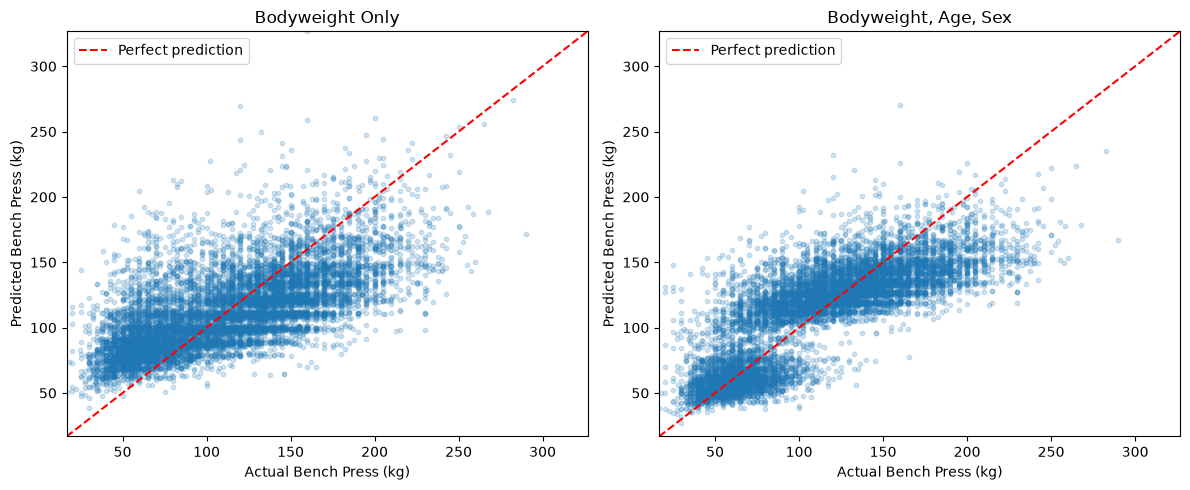

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Determine common axis limits for both plots
min_val = min(y_test.min(), body_predictions.min(), full_predictions.min())
max_val = max(y_test.max(), body_predictions.max(), full_predictions.max())

# Plot predictions for both models
models = [
    ("Bodyweight Only", body_predictions),
    ("Bodyweight, Age, Sex", full_predictions)
]

for ax, (title, predictions) in zip(axes, models):
    ax.scatter(y_test, predictions, alpha=0.2, s=10)
    ax.plot([min_val, max_val], [min_val, max_val], "r--",
            label="Perfect prediction")

    ax.set_title(title)
    ax.set_xlabel("Actual Bench Press (kg)")
    ax.set_ylabel("Predicted Bench Press (kg)")
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    ax.legend()

plt.tight_layout()
plt.show()